<a href="https://colab.research.google.com/github/2Bert0/previsao-atraso-entregas-ml/blob/main/An%C3%A1lise_Operacional_de_Giro%2C_Receita_e_Frete_por_Categoria_Produto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import kagglehub
import pandas as pd

# Baixa a base pública da Olist e carrega as tabelas de pedidos, itens e produtos
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

orders = pd.read_csv(os.path.join(path, "olist_orders_dataset.csv"))
items = pd.read_csv(os.path.join(path, "olist_order_items_dataset.csv"))
products = pd.read_csv(os.path.join(path, "olist_products_dataset.csv"))

# Mantém apenas pedidos que não foram cancelados para não inflar vendas irreais
pedidos_validos = orders[orders["order_status"] != "canceled"][
    ["order_id", "order_status", "order_purchase_timestamp"]
].copy()

# Junta itens vendidos aos pedidos válidos (granularidade no nível de item de pedido)
vendas = items.merge(pedidos_validos, on="order_id", how="inner")

# Enriquece com categoria e peso do produto para análise operacional/comercial
vendas = vendas.merge(
    products[["product_id", "product_category_name", "product_weight_g"]],
    on="product_id",
    how="left",
)

vendas["data_compra"] = pd.to_datetime(vendas["order_purchase_timestamp"])
vendas["mes_compra"] = vendas["data_compra"].dt.month

print("Total de linhas de itens vendidos:", len(vendas))
print("Categorias únicas:", vendas["product_category_name"].nunique())

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Total de linhas de itens vendidos: 112108
Categorias únicas: 73


In [ ]:
# Preenche categoria ausente para não perder esses itens na visão geral de vendas
vendas_cat = vendas.assign(
    categoria=vendas["product_category_name"].fillna("sem_categoria")
)

# Agrega no nível de categoria para medir volume (giro), receita e frete
resumo_cat = (
    vendas_cat.groupby("categoria", as_index=False)
    .agg(
        itens_vendidos=("order_item_id", "count"),
        pedidos_unicos=("order_id", "nunique"),
        receita_total=("price", "sum"),
        frete_total=("freight_value", "sum"),
        ticket_medio=("price", "mean"),
    )
)

# Calcula o peso do frete sobre a receita da categoria (evita divisão por zero)
resumo_cat["peso_frete"] = resumo_cat["frete_total"] / resumo_cat[
    "receita_total"
].replace(0, float("nan"))

# Classifica o giro relativo (acima ou abaixo da mediana) para separar volume de ticket alto
mediana_giro = resumo_cat["itens_vendidos"].median()
resumo_cat["perfil_giro"] = resumo_cat["itens_vendidos"].apply(
    lambda x: "Alto Giro" if x >= mediana_giro else "Baixo Giro"
)

top_receita = resumo_cat.sort_values("receita_total", ascending=False).head(10)
print("Top 10 categorias por receita total:")
print(
    top_receita[[
        "categoria",
        "itens_vendidos",
        "receita_total",
        "ticket_medio",
        "peso_frete",
        "perfil_giro",
    ]].round(2)
)

Top 10 categorias por receita total:
                 categoria  itens_vendidos  receita_total  ticket_medio  \
11            beleza_saude            9634     1255695.13        130.34   
66      relogios_presentes            5970     1198185.21        200.70   
13         cama_mesa_banho           11097     1035964.06         93.36   
32           esporte_lazer            8590      979740.92        114.06   
44  informatica_acessorios            7781      904322.02        116.22   
54        moveis_decoracao            8298      727465.05         87.67   
73   utilidades_domesticas            6915      626825.80         90.65   
26              cool_stuff            3780      620835.39        164.24   
8               automotivo            4205      586620.73        139.51   
40      ferramentas_jardim            4328      481009.94        111.14   

    peso_frete perfil_giro  
11        0.14   Alto Giro  
66        0.08   Alto Giro  
13        0.20   Alto Giro  
32        0.17   Alto

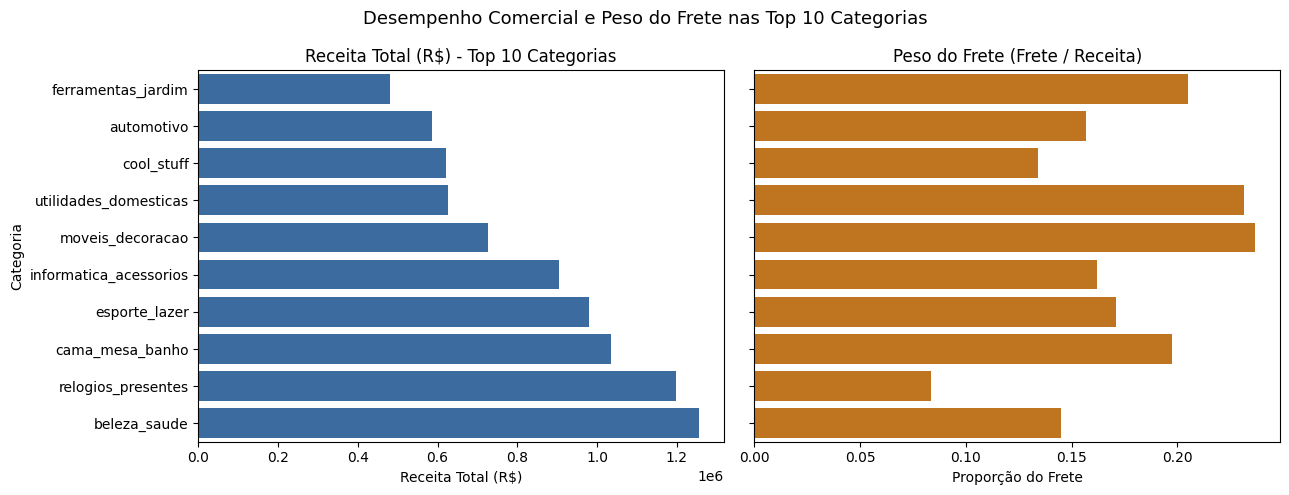

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ordena do menor para o maior para que o maior fique no topo no gráfico horizontal
plot_df = top_receita.sort_values("receita_total", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

# Painel 1: Receita total por categoria (foco em faturamento)
sns.barplot(
    data=plot_df,
    x="receita_total",
    y="categoria",
    ax=axes[0],
    color="#2b6cb0",
)
axes[0].set_title("Receita Total (R$) - Top 10 Categorias")
axes[0].set_xlabel("Receita Total (R$)")
axes[0].set_ylabel("Categoria")

# Painel 2: Peso do frete (frete / receita) para detectar atrito logístico
sns.barplot(
    data=plot_df,
    x="peso_frete",
    y="categoria",
    ax=axes[1],
    color="#d97706",
)
axes[1].set_title("Peso do Frete (Frete / Receita)")
axes[1].set_xlabel("Proporção do Frete")
axes[1].set_ylabel("")

plt.suptitle(
    "Desempenho Comercial e Peso do Frete nas Top 10 Categorias", fontsize=13
)
plt.tight_layout()

# Salva em alta resolução antes de exibir para não perder qualidade no GitHub
plt.savefig("analise_categorias_frete.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Agrega no nível de produto para identificar itens de alto vs. baixo giro
resumo_prod = (
    vendas_cat.groupby(
        ["product_id", "categoria"], as_index=False
    )
    .agg(
        unidades_vendidas=("order_item_id", "count"),
        receita_prod=("price", "sum"),
        frete_prod=("freight_value", "sum"),
    )
    .sort_values("unidades_vendidas", ascending=False)
)

# Calcula participação acumulada nas unidades vendidas (lógica tipo Pareto)
total_unidades = resumo_prod["unidades_vendidas"].sum()
resumo_prod["pct_acumulado_giro"] = (
    resumo_prod["unidades_vendidas"].cumsum() / total_unidades
)

top_20_pct_qtd = int(len(resumo_prod) * 0.2)
giro_top_20_pct = (
    resumo_prod.iloc[:top_20_pct_qtd]["unidades_vendidas"].sum()
    / total_unidades
    * 100
)

print(f"Total de SKUs/produtos distintos com venda: {len(resumo_prod)}")
print(
    f"Os 20% produtos mais vendidos ({top_20_pct_qtd} itens) respondem por "
    f"{giro_top_20_pct:.1f}% de todo o giro de unidades."
)

Total de SKUs/produtos distintos com venda: 32735
Os 20% produtos mais vendidos (6547 itens) respondem por 67.2% de todo o giro de unidades.


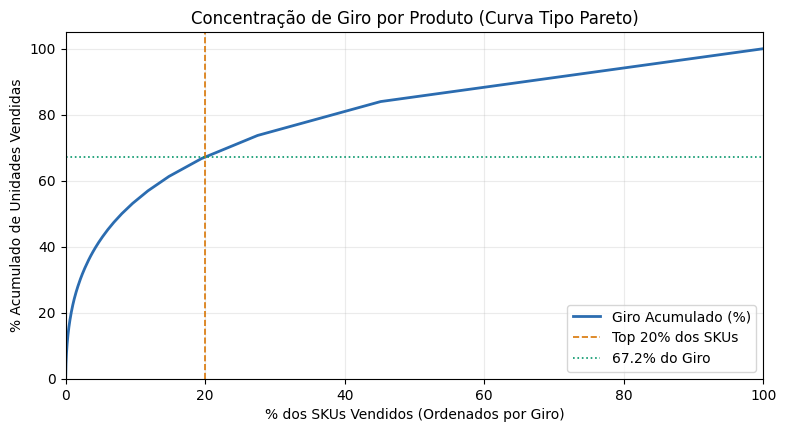

Arquivos salvos com sucesso.


In [ ]:
import matplotlib.pyplot as plt

# Exporta tabelas agregadas para reutilizar em BI, revisão ou repositório
resumo_cat.to_csv("resumo_categorias_giro_frete.csv", index=False)
resumo_prod.to_csv("resumo_produtos_pareto.csv", index=False)

# Gera curva acumulada de giro por posição percentual dos SKUs
pos_pct = (
    pd.Series(range(1, len(resumo_prod) + 1)) / len(resumo_prod)
) * 100
acum_giro_pct = resumo_prod["pct_acumulado_giro"].values * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    pos_pct, acum_giro_pct, color="#2b6cb0", linewidth=2, label="Giro Acumulado (%)"
)
ax.axvline(
    20, color="#d97706", linestyle="--", linewidth=1.2, label="Top 20% dos SKUs"
)
ax.axhline(
    giro_top_20_pct,
    color="#059669",
    linestyle=":",
    linewidth=1.2,
    label=f"{giro_top_20_pct:.1f}% do Giro",
)

ax.set_title("Concentração de Giro por Produto (Curva Tipo Pareto)")
ax.set_xlabel("% dos SKUs Vendidos (Ordenados por Giro)")
ax.set_ylabel("% Acumulado de Unidades Vendidas")
ax.set_xlim(0, 100)
ax.set_ylim(0, 105)
ax.legend(loc="lower right")
ax.grid(alpha=0.25)

# Salva em alta resolução antes de exibir
plt.savefig("curva_pareto_giro_produtos.png", dpi=300, bbox_inches="tight")
plt.show()

print("Arquivos salvos com sucesso.")